How are in-demand skills trending for Data Analysts?

Methodolgy
1. Aggregate skill counts monthly
2. Re- analyze based on percentage of total jobs
3. Plot the monthly skill demand


In [1]:
# importing Librarires
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset


#loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\Dell\anaconda3\envs\Best_Room\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_DA_US = df[(df['job_title'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()

In [6]:
df_DA_US['job_posted_month_no'] = df_DA_US['job_posted_date'].dt.month

In [7]:
df_DA_US_explode = df_DA_US.explode('job_skills')

In [11]:
df_DA_US_pivot = df_DA_US_explode.pivot_table(index='job_posted_month_no', columns= 'job_skills', aggfunc='size', fill_value= 0)

df_DA_US_pivot.loc['Total'] = df_DA_US_pivot.sum()

df_DA_US_pivot = df_DA_US_pivot[df_DA_US_pivot.loc['Total'].sort_values(ascending= False).index]

df_DA_US_pivot = df_DA_US_pivot.drop('Total')

In [12]:
DA_totals = df_DA_US.groupby('job_posted_month_no').size()

In [16]:
df_DA_US_percent = df_DA_US_pivot.div(DA_totals/100, axis=0)

In [18]:

df_DA_US_percent = df_DA_US_percent.reset_index()

df_DA_US_percent['job_posted_month'] = df_DA_US_percent['job_posted_month_no'].apply(
    lambda x: pd.to_datetime(x, format='%m').strftime('%b')
)

df_DA_US_percent = df_DA_US_percent.set_index('job_posted_month')

df_DA_US_percent = df_DA_US_percent.drop(columns='job_posted_month_no')


C:\Users\Dell\AppData\Local\Temp\ipykernel_19888\3009087661.py:4: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  lambda x: pd.to_datetime(x, format='%m').strftime('%b')


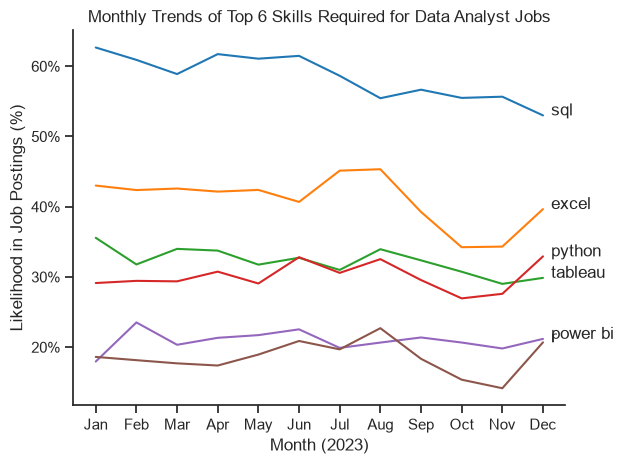

In [33]:


sns.set_theme(style='ticks')


# Select the top 6 skills
top_6_skills = df_DA_US_percent.max().nlargest(6).index

df_plot = df_DA_US_percent[top_6_skills]

# Create line plot
sns.lineplot(data=df_plot, dashes=False, palette='tab10')
sns.despine(top=True, right=True)

plt.title('Monthly Trends of Top 6 Skills Required for Data Analyst Jobs')
plt.xlabel('Month (2023)')
plt.ylabel('Likelihood in Job Postings (%)')

# Remove the legend
plt.legend().remove()

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

# Label each line at its final data point
for i in range(6):
    plt.text(
        11.2,
        df_plot.iloc[-1, i],
        df_plot.columns[i]
    )

plt.tight_layout()
plt.show()